# Member 5: Feature Group Ablation and Prediction Intervals (MSFT)

**Name:** Alfred Njaku &nbsp;&nbsp; **Student ID:** 160819 &nbsp;&nbsp; **Branch:** `member-5-ablation-intervals`

This notebook covers the Intermediate tasks that belong to Member 5:

1. **Feature group ablation**: which groups of predictors help the next-day return forecast, and which do not (Notebook 4, Step 8). This also answers **Exercise 4**.
2. **A new feature of my own**, checked with `check_no_lookahead` before it is evaluated (**Exercise 3**).
3. **Prediction intervals**: a 10% to 90% range from quantile regression, its **coverage**, and whether the model is overconfident (Notebook 4, Step 10).

**What I reuse from the team, unchanged:**

| From | What | Value |
|:--|:--|:--|
| Member 1 | MSFT and predictor data in `data/` | snapshot 2015-01-02 to 2026-11-09 |
| Member 4 | Ridge `alpha`, tuned on the first 1,000 days only | 1000 |
| Member 4 | Gradient boosting `max_depth`, `learning_rate`, tuned on the first 1,000 days only | 2, 0.01 |

I do **not** re-tune anything on the test period. I reuse Member 4's frozen settings, so that my results are comparable with `outputs/model_comparison.csv`.

## Step 1: Set up

In [17]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

from tslab import config
from tslab.data import load_market_data
from tslab.features import (build_features, make_dataset, check_no_lookahead,
                            FEATURE_GROUPS, ALL_FEATURES)
from tslab.validation import walk_forward_splits, walk_forward_predict
from tslab.metrics import out_of_sample_r2, diebold_mariano

import warnings
warnings.filterwarnings("ignore")

np.random.seed(config.SEED)
os.makedirs(config.OUTPUT_DIR, exist_ok=True)
print("Target stock:", config.TARGET_TICKER)

Target stock: MSFT


In [18]:
# The same modelling table and the same walk-forward folds as Notebook 4,
# so every number here is scored on exactly the same test days as Member 4's.
frame = load_market_data()
dataset = make_dataset(frame, horizon=1).dropna(subset=["target_return"])

X = dataset[ALL_FEATURES]
y = dataset["target_return"]
splits = list(walk_forward_splits(len(dataset), config.INITIAL_TRAIN, config.TEST_SIZE))

print("Rows in the modelling table:", len(dataset))
print("Predictors                 :", len(ALL_FEATURES), "in", len(FEATURE_GROUPS), "groups")
print("Walk-forward folds         :", len(splits))
print("Test days                  :", sum(len(test) for _, test in splits),
      f"({dataset.index[splits[0][1][0]].date()} to {dataset.index[-1].date()})")

Loaded 2981 trading days of MSFT, 2015-01-02 to 2026-11-09, with 7 predictor series.
Rows in the modelling table: 2781
Predictors                 : 47 in 6 groups
Walk-forward folds         : 29
Test days                  : 1781 (2019-10-08 to 2026-11-06)


## Step 2: Reuse Member 4's frozen hyperparameters

These values were chosen by Member 4 in Notebook 4, Step 6, using **only the first 1,000 days** (before the first test day). Reusing them keeps the test honest: nothing in this notebook is chosen by looking at the test period.

In [19]:
BEST_ALPHA = 1000                 # Ridge penalty (Member 4, Step 6)
BEST_DEPTH, BEST_RATE = 2, 0.01   # gradient boosting (Member 4, Step 6)

def make_boosting(max_depth=3, learning_rate=0.03, max_iter=200, loss="squared_error", quantile=None):
    # Identical to make_boosting in Notebook 4, so that results are comparable.
    return HistGradientBoostingRegressor(
        loss=loss, quantile=quantile,
        max_depth=max_depth, learning_rate=learning_rate, max_iter=max_iter,
        min_samples_leaf=40, l2_regularization=1.0, random_state=config.SEED,
    )

ridge_factory = lambda: Ridge(alpha=BEST_ALPHA)
boosting_factory = lambda: make_boosting(max_depth=BEST_DEPTH, learning_rate=BEST_RATE)

In [20]:
# Sanity check: with all features, my predictions must match the ones Member 4
# saved. If they do, my ablation starts from the same model as the team's results.
saved = pd.read_csv(config.OUTPUT_DIR / "predictions_ml.csv", index_col=0, parse_dates=True)

full_ridge = walk_forward_predict(ridge_factory, X, y, splits)
full_gb = walk_forward_predict(boosting_factory, X, y, splits)

for name, mine in [("Ridge", full_ridge), ("Gradient boosting", full_gb)]:
    gap = (mine - saved[name].reindex(mine.index)).abs().max()
    print(f"{name:18s} largest difference from Member 4's saved predictions: {gap:.2e}")
print("Differences close to zero (below about 0.001) only come from slightly different library versions.")

Ridge              largest difference from Member 4's saved predictions: 0.00e+00
Gradient boosting  largest difference from Member 4's saved predictions: 0.00e+00
Differences close to zero (below about 0.001) only come from slightly different library versions.


## Step 3: Feature group ablation

An **ablation** removes one part of a model at a time and measures what changes. Here the parts are the six **feature groups** (returns, volatility, technical, volume, other_markets, calendar).

For each group I run two walk-forward tests:

| Test | Question it answers |
|:--|:--|
| **Only this group** | Can this group predict anything on its own? |
| **Without this group** | Does the model still need this group once it has all the others? |

The score is the **out-of-sample R²** against the naive (zero-return) forecast: positive means better than naive, negative means worse.

The lab warns that *"a very small R² difference is not a finding"*. So for every "without" model I also run a **Diebold-Mariano test against the all-features model**. If the p-value is above 0.05, removing that group made no difference that we can tell apart from luck.

In [21]:
def run_ablation(model_factory, model_name, full_predictions):
    # Score only the days on which the all-features model made a prediction.
    mask = full_predictions.notna()
    actual = y[mask]
    full_r2 = out_of_sample_r2(actual, full_predictions[mask])

    rows = []
    for group, names in FEATURE_GROUPS.items():
        others = [f for f in ALL_FEATURES if f not in names]
        only = walk_forward_predict(model_factory, dataset[names], y, splits)[mask]
        without = walk_forward_predict(model_factory, dataset[others], y, splits)[mask]

        # DM test: "without this group" (A) against "all features" (B).
        # Negative statistic = removing the group made the errors SMALLER.
        dm_stat, dm_p = diebold_mariano(actual, without, full_predictions[mask])
        rows.append({
            "Model": model_name,
            "Group": group,
            "Features in group": len(names),
            "R2 using ONLY this group": out_of_sample_r2(actual, only),
            "R2 WITHOUT this group": out_of_sample_r2(actual, without),
            "R2 change when removed": out_of_sample_r2(actual, without) - full_r2,
            "DM stat (without vs all)": dm_stat,
            "DM p-value (without vs all)": dm_p,
        })
    table = pd.DataFrame(rows)
    table["Removing it is significant?"] = np.where(table["DM p-value (without vs all)"] < 0.05, "Yes", "No")
    return table, full_r2

started = time.time()
ablation_ridge, full_r2_ridge = run_ablation(ridge_factory, "Ridge", full_ridge)
ablation_gb, full_r2_gb = run_ablation(boosting_factory, "Gradient boosting", full_gb)
print(f"Ablation finished in {time.time() - started:.0f} seconds")
print(f"R2 with ALL features: Ridge {full_r2_ridge:.5f}, Gradient boosting {full_r2_gb:.5f}")

ablation = pd.concat([ablation_ridge, ablation_gb], ignore_index=True)
ablation.round(5)

Ablation finished in 38 seconds
R2 with ALL features: Ridge -0.01664, Gradient boosting -0.00713


,Model,Group,Features in group,R2 using ONLY this group,R2 WITHOUT this group,R2 change when removed,DM stat (without vs all),DM p-value (without vs all),Removing it is significant?
0,Ridge,returns,9,-0.00467,-0.01023,0.00641,-1.83695,0.06638,No
1,Ridge,volatility,6,0.00224,-0.01703,-0.00039,0.11442,0.90892,No
2,Ridge,technical,9,-0.00699,-0.00627,0.01037,-2.59391,0.00957,Yes
3,Ridge,volume,1,0.00135,-0.01642,0.00023,-0.74531,0.45618,No
4,Ridge,other_markets,15,0.00278,-0.01811,-0.00147,0.33767,0.73565,No
5,Ridge,calendar,7,0.00019,-0.01482,0.00182,-1.38813,0.16527,No
6,Gradient boosting,returns,9,-0.01510,-0.00725,-0.00012,0.04581,0.96347,No
7,Gradient boosting,volatility,6,-0.00112,-0.00817,-0.00105,0.34939,0.72683,No
8,Gradient boosting,technical,9,-0.00667,-0.00639,0.00074,-0.12669,0.89920,No
9,Gradient boosting,volume,1,-0.00459,-0.00723,-0.00010,0.19365,0.84647,No


In [22]:
# Save the table for Member 6 (Power BI and the final report).
ablation.round(6).to_csv(config.OUTPUT_DIR / "feature_ablation.csv", index=False)
print("Saved", config.OUTPUT_DIR / "feature_ablation.csv")

Saved C:\Users\thuku\TimeSeriesForecasting-C1\outputs\feature_ablation.csv


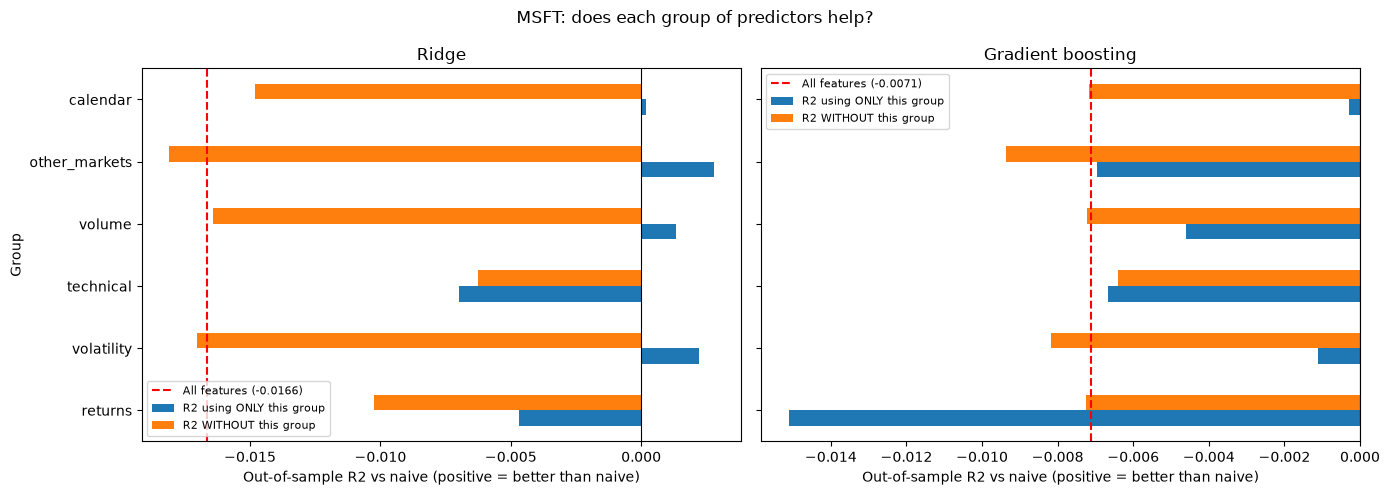

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, table, full_r2) in zip(axes, [("Ridge", ablation_ridge, full_r2_ridge),
                                              ("Gradient boosting", ablation_gb, full_r2_gb)]):
    table.set_index("Group")[["R2 using ONLY this group", "R2 WITHOUT this group"]].plot.barh(ax=ax)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.axvline(full_r2, color="red", linestyle="--", label=f"All features ({full_r2:.4f})")
    ax.set_title(name)
    ax.set_xlabel("Out-of-sample R2 vs naive (positive = better than naive)")
    ax.legend(fontsize=8)
fig.suptitle(f"{config.TARGET_TICKER}: does each group of predictors help?")
fig.tight_layout()
fig.savefig(config.OUTPUT_DIR / "feature_ablation.png", dpi=120)
plt.show()

In [24]:
# Exercise 4: do Ridge and gradient boosting agree on which groups matter?
# Spearman rank correlation of the "R2 change when removed" column:
# +1 = same ranking, 0 = no relation, -1 = opposite ranking.
agree = pd.DataFrame({
    "Ridge: R2 change when removed": ablation_ridge.set_index("Group")["R2 change when removed"],
    "GB: R2 change when removed": ablation_gb.set_index("Group")["R2 change when removed"],
})
rho, rho_p = stats.spearmanr(agree.iloc[:, 0], agree.iloc[:, 1])
print(f"Spearman rank correlation between the two models' rankings: {rho:.2f} (p = {rho_p:.2f}, only 6 groups)")
agree.round(5)

Spearman rank correlation between the two models' rankings: 0.83 (p = 0.04, only 6 groups)


,Ridge: R2 change when removed,GB: R2 change when removed
Group,,
returns,0.00641,-0.00012
volatility,-0.00039,-0.00105
technical,0.01037,0.00074
volume,0.00023,-0.00010
other_markets,-0.00147,-0.00223
calendar,0.00182,-0.00003


### My interpretation of the ablation

**1. All features.** With all 47 predictors, the out-of-sample R² is **-0.01664 for Ridge** and **-0.00713 for gradient boosting**. Both are negative, so neither model beats the naive "no change" forecast on the 1,781 test days. This agrees with Member 4's Diebold-Mariano results.

**2. Groups on their own.** With Ridge, four groups score slightly above zero on their own: other_markets (+0.0028), volatility (+0.0022), volume (+0.0014) and calendar (+0.0002). These are tiny, less than 0.3% of the variation in daily returns. With gradient boosting, no group scores above zero on its own.

**3. Removing a group.**
- **Ridge:** removing the **technical** group *raises* R² by 0.0104 (from -0.0166 to -0.0063), and the DM test says this is significant (p = 0.0096). The 9 technical features (RSI, MACD, Bollinger Bands, distances from moving averages, and so on) were adding noise rather than signal. Removing the returns group also raises R² (+0.0064), but p = 0.066, so this is not significant at the 5% level. Removing other_markets or volatility lowers R² very slightly (-0.0015 and -0.0004), but these changes are far from significant (p = 0.74 and 0.91).
- **Gradient boosting:** every change is smaller than 0.0025, and every DM p-value is above 0.6. With the strong regularisation that Member 4 chose (depth 2, learning rate 0.01), the model makes very cautious predictions close to the average, so removing any group changes almost nothing.

**4. Do the two models agree? (Exercise 4)** Mostly. The Spearman rank correlation of the "R² change when removed" column is **0.83**. Both models say that other_markets is the group whose removal hurts most, and that the technical group is the least useful. They differ in size: Ridge reacts strongly to the technical group, while boosting hardly reacts to anything. Ridge is linear and spreads its weight across many correlated, noisy features, so a block of noisy features hurts it more. Boosting only splits on a feature when it improves the fit, so it ignores weak features by itself. With only 6 groups, the ranking is a hint, not a proof.

**5. Conclusion for the portfolio manager.** No group of predictors gives a reliable edge over the naive forecast for MSFT. The other markets (S&P 500, technology fund, VIX and so on) are the most useful group, but their contribution is too small to be a finding. The only significant result is that the technical indicators make Ridge *worse*. Even without them, Ridge's R² is still negative (-0.0063), so it still does not beat the naive forecast.

## Step 4: A new feature of my own (Exercise 3)

**Idea:** a *volume trend* feature, `volume_ratio_10_60` = the 10-day average volume divided by the 60-day average volume (as a log). A value above 0 means trading has been heavier than usual for two weeks, which can come before or during big moves.

The lab rule is: *run the look-ahead test on every feature that you add*, **before** evaluating it. I do not edit `tslab/features.py` (a shared file that the whole team imports). Instead I wrap `build_features` in my own function and pass it to `check_no_lookahead`.

In [25]:
def features_with_volume_trend(market):
    out = build_features(market)
    volume = market["Volume"]
    # Uses only today's and PAST volumes: rolling windows look backwards.
    out["volume_ratio_10_60"] = np.log(volume.rolling(10).mean() / volume.rolling(60).mean())
    return out

# 1) Look-ahead test FIRST. It stops with an error if any feature peeks at the future.
check_no_lookahead(frame, feature_function=features_with_volume_trend, n_checks=8)

True

In [26]:
# 2) Only after the test passes: add the feature and re-run the walk-forward test.
new_table = features_with_volume_trend(frame).reindex(dataset.index)
X_new = pd.concat([X, new_table[["volume_ratio_10_60"]]], axis=1)
print("Missing values in the new feature:", int(X_new["volume_ratio_10_60"].isna().sum()))

rows = []
for name, factory, full_pred in [("Ridge", ridge_factory, full_ridge),
                                 ("Gradient boosting", boosting_factory, full_gb)]:
    with_new = walk_forward_predict(factory, X_new, y, splits)
    mask = full_pred.notna()
    dm_stat, dm_p = diebold_mariano(y[mask], with_new[mask], full_pred[mask])
    rows.append({"Model": name,
                 "R2 all features": out_of_sample_r2(y[mask], full_pred[mask]),
                 "R2 all + volume_ratio_10_60": out_of_sample_r2(y[mask], with_new[mask]),
                 "DM stat (new vs all)": dm_stat,
                 "DM p-value (new vs all)": dm_p})
new_feature_result = pd.DataFrame(rows).set_index("Model")
new_feature_result.round(5)

Missing values in the new feature: 0


,R2 all features,R2 all + volume_ratio_10_60,DM stat (new vs all),DM p-value (new vs all)
Model,,,,
Ridge,-0.01664,-0.01591,-1.77471,0.07612
Gradient boosting,-0.00713,-0.00535,-2.05085,0.04043


### My interpretation of the new feature

- **Look-ahead test:** the new feature `volume_ratio_10_60` **passed** `check_no_lookahead` on 8 random dates. Its value did not change when the future was deleted, because both rolling averages only use today and earlier days. The test has to come **before** looking at R², because a leaky feature can produce an excellent-looking R² (Member 4 showed R² jumping to about 0.79 with a leak). Testing first keeps the result from tempting us into keeping a feature that cheats.
- **Did it help?** Adding it moved R² from -0.0166 to -0.0159 for Ridge and from -0.0070 to -0.0053 for gradient boosting. The DM statistics are negative (smaller errors), but the p-values are **0.076 and 0.056**, both above 0.05, so the improvement could be luck. Both R² values are also still negative, so the models still do not beat the naive forecast.
- **Should the team keep it?** No. The gain is not significant. Also, choosing it *because* it scored better on the test period would be a form of tuning on the test period, which the lab rules forbid.

## Step 5: Prediction intervals with quantile regression

A point forecast ("tomorrow's return will be +0.05%") says nothing about how sure the model is. I train two extra gradient boosting models with the **pinball (quantile) loss**:

- the **q10** model predicts the 10th percentile of tomorrow's log return,
- the **q90** model predicts the 90th percentile.

If the model is well calibrated, the actual return should land between q10 and q90 on about **80%** of the days, below q10 on about 10%, and above q90 on about 10%.

I use the same settings as Notebook 4, Step 10 (so the numbers match `predictions_ml.csv`), and the same walk-forward folds: the quantile models are refitted on each training block and never see the test days.

In [27]:
started = time.time()
q10 = walk_forward_predict(lambda: make_boosting(loss="quantile", quantile=0.10), X, y, splits)
q90 = walk_forward_predict(lambda: make_boosting(loss="quantile", quantile=0.90), X, y, splits)
print(f"Quantile models finished in {time.time() - started:.1f} seconds")

scored = q10.notna() & q90.notna()
iv = pd.DataFrame({
    "close": dataset["close"],
    "actual_close_next": dataset["target_close"],
    "actual_return": y,
    "q10_return": q10,
    "q90_return": q90,
    "vol_21d": dataset["vol_21d"],   # known on the forecast day; used only to group days
})[scored]

# Convert the return range into a price range: close today * exp(return).
iv["lower_price"] = iv["close"] * np.exp(iv["q10_return"])
iv["upper_price"] = iv["close"] * np.exp(iv["q90_return"])
iv["inside"] = (iv["actual_return"] >= iv["q10_return"]) & (iv["actual_return"] <= iv["q90_return"])
iv["below_q10"] = iv["actual_return"] < iv["q10_return"]
iv["above_q90"] = iv["actual_return"] > iv["q90_return"]
iv["width_pct"] = (np.exp(iv["q90_return"]) - np.exp(iv["q10_return"])) * 100

print("Days scored:", len(iv))
print("Days where q10 > q90 (crossed quantiles):", int((iv["q10_return"] > iv["q90_return"]).sum()))

Quantile models finished in 15.5 seconds
Days scored: 1781
Days where q10 > q90 (crossed quantiles): 0


In [28]:
n, hits = len(iv), int(iv["inside"].sum())
test = stats.binomtest(hits, n, 0.80)   # is the coverage different from 80%?

coverage_summary = pd.Series({
    "Days scored": n,
    "Coverage (inside q10 to q90)": iv["inside"].mean(),
    "Target coverage": 0.80,
    "Share below q10 (target 0.10)": iv["below_q10"].mean(),
    "Share above q90 (target 0.10)": iv["above_q90"].mean(),
    "Binomial test p-value (coverage = 80%?)": test.pvalue,
    "95% CI of coverage, low": test.proportion_ci().low,
    "95% CI of coverage, high": test.proportion_ci().high,
    "Average interval width (% of price)": iv["width_pct"].mean(),
    "Average interval width ($)": (iv["upper_price"] - iv["lower_price"]).mean(),
}, name="Value")
coverage_summary.round(4).to_frame()

,Value
Days scored,1781.0000
Coverage (inside q10 to q90),0.7586
Target coverage,0.8000
Share below q10 (target 0.10),0.1140
Share above q90 (target 0.10),0.1275
Binomial test p-value (coverage = 80%?),0.0000
"95% CI of coverage, low",0.7380
"95% CI of coverage, high",0.7783
Average interval width (% of price),3.7659
Average interval width ($),11.8303


### Where does the interval fail? Coverage by volatility regime and by year

Notebook 2 (Member 2) found **volatility clustering**: calm days follow calm days and stormy days follow stormy days. If the intervals do not widen enough in stormy periods, coverage will be lowest exactly when the risk is highest. I split the test days into three equal groups by the 21-day volatility **known on the forecast day**.

In [29]:
iv["volatility_regime"] = pd.qcut(iv["vol_21d"], 3, labels=["Calm", "Normal", "Stormy"])

by_regime = iv.groupby("volatility_regime", observed=True).agg(
    days=("inside", "size"),
    coverage=("inside", "mean"),
    below_q10=("below_q10", "mean"),
    above_q90=("above_q90", "mean"),
    avg_width_pct=("width_pct", "mean"),
)
by_year = iv.groupby(iv.index.year).agg(
    days=("inside", "size"),
    coverage=("inside", "mean"),
    avg_width_pct=("width_pct", "mean"),
)
by_year.index.name = "year"
display(by_regime.round(3))
display(by_year.round(3))

,days,coverage,below_q10,above_q90,avg_width_pct
volatility_regime,,,,,
Calm,594,0.778,0.111,0.111,2.937
Normal,593,0.749,0.099,0.152,3.697
Stormy,594,0.749,0.131,0.120,4.664


,days,coverage,avg_width_pct
year,,,
2019,59,0.746,2.030
2020,253,0.692,4.338
2021,252,0.794,3.255
2022,251,0.749,5.162
2023,250,0.736,3.585
2024,252,0.790,3.018
2025,250,0.824,3.523
2026,214,0.724,3.909


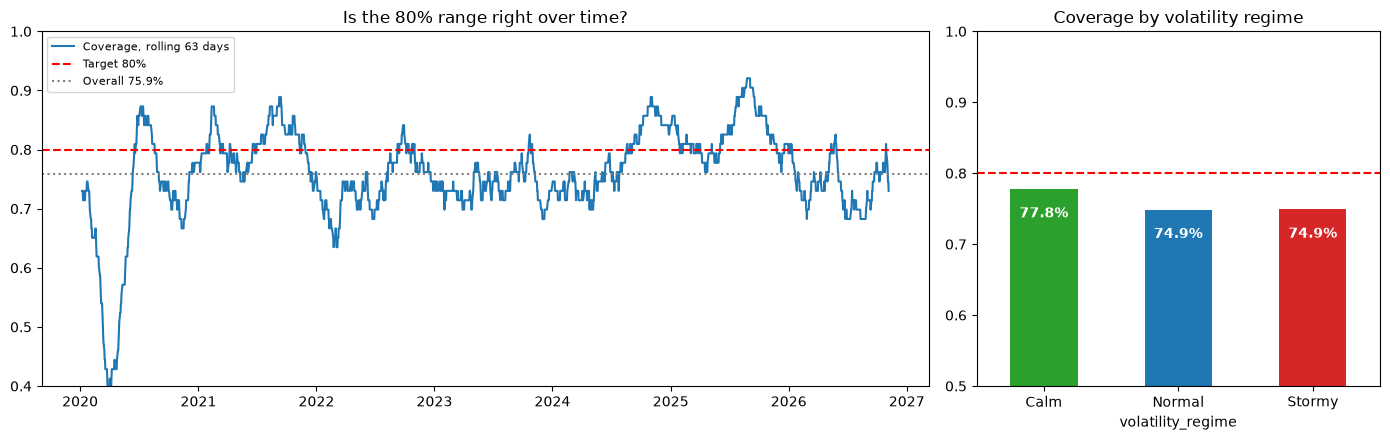

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

rolling = iv["inside"].astype(float).rolling(63).mean()
axes[0].plot(rolling.index, rolling, color="tab:blue", label="Coverage, rolling 63 days")
axes[0].axhline(0.80, color="red", linestyle="--", label="Target 80%")
axes[0].axhline(iv["inside"].mean(), color="grey", linestyle=":", label=f"Overall {iv['inside'].mean():.1%}")
axes[0].set_ylim(0.4, 1.0); axes[0].set_title("Is the 80% range right over time?"); axes[0].legend(fontsize=8)

by_regime["coverage"].plot.bar(ax=axes[1], color=["tab:green", "tab:blue", "tab:red"], rot=0)
axes[1].axhline(0.80, color="red", linestyle="--")
axes[1].set_ylim(0.5, 1.0); axes[1].set_title("Coverage by volatility regime")
for i, v in enumerate(by_regime["coverage"]):
    axes[1].text(i, v - 0.04, f"{v:.1%}", ha="center", color="white", fontweight="bold")
fig.tight_layout()
fig.savefig(config.OUTPUT_DIR / "interval_coverage.png", dpi=120)
plt.show()

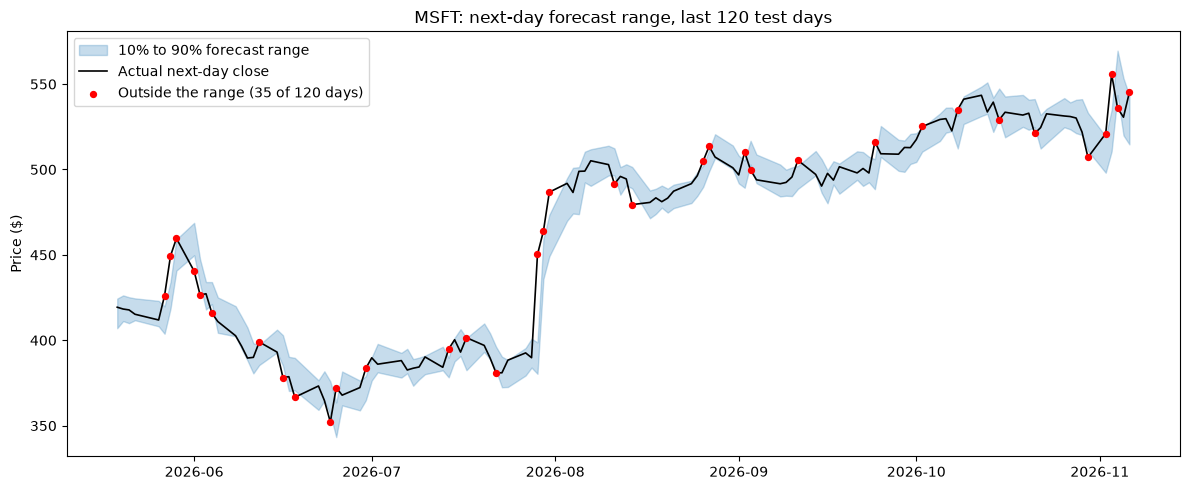

In [31]:
recent = iv.iloc[-120:]
plt.figure(figsize=(12, 5))
plt.fill_between(recent.index, recent["lower_price"], recent["upper_price"],
                 color="tab:blue", alpha=0.25, label="10% to 90% forecast range")
plt.plot(recent.index, recent["actual_close_next"], color="black", linewidth=1.2, label="Actual next-day close")
misses = recent[~recent["inside"]]
plt.scatter(misses.index, misses["actual_close_next"], color="red", s=18, zorder=3,
            label=f"Outside the range ({len(misses)} of {len(recent)} days)")
plt.title(f"{config.TARGET_TICKER}: next-day forecast range, last 120 test days")
plt.ylabel("Price ($)"); plt.legend(); plt.tight_layout()
plt.savefig(config.OUTPUT_DIR / "prediction_intervals.png", dpi=120)
plt.show()

In [32]:
# Save for Member 6 (Power BI and the 63-day forecast range).
export = iv[["close", "actual_close_next", "actual_return", "q10_return", "q90_return",
             "lower_price", "upper_price", "inside", "volatility_regime", "width_pct"]].copy()
export.index.name = "date"
export.round(6).to_csv(config.OUTPUT_DIR / "prediction_intervals.csv")

summary_out = coverage_summary.to_frame().T
summary_out.round(6).to_csv(config.OUTPUT_DIR / "interval_coverage_summary.csv", index=False)
by_regime.round(6).to_csv(config.OUTPUT_DIR / "interval_coverage_by_regime.csv")
print("Saved prediction_intervals.csv, interval_coverage_summary.csv and interval_coverage_by_regime.csv to", config.OUTPUT_DIR)

Saved prediction_intervals.csv, interval_coverage_summary.csv and interval_coverage_by_regime.csv to C:\Users\thuku\TimeSeriesForecasting-C1\outputs


### My interpretation of the intervals

**1. Coverage.** The actual next-day return fell inside the 10% to 90% range on **75.9%** of the 1,781 test days, against a target of 80%. The 95% confidence interval for the coverage is **73.9% to 77.9%**, which does not include 80%. The binomial test p-value is below 0.001, so the shortfall is not luck.

**2. Which side fails?** The actual return was below q10 on **11.2%** of days and above q90 on **12.9%** of days, against 10% each. The range is too narrow on **both** sides, and a little more on the upside. The model underestimates MSFT's big up days (for example after earnings) slightly more than its big down days.

**3. Calm vs stormy periods.** Coverage is **78.3%** on calm days, **74.9%** on normal days and **74.6%** on stormy days. The range does widen when volatility is high (average width 2.9% on calm days, 4.7% on stormy days), but **not enough**. This matches the volatility clustering that Member 2 found: volatile days come in clusters, and a model trained mostly on calmer history reacts too slowly when a storm starts. The worst year was **2020 (70.0%)**. During the COVID crash in March 2020, the rolling 63-day coverage fell to about 42%. In 2021 and 2025 coverage was close to or above 80%.

**4. Verdict.** The model is **overconfident**: its ranges are somewhat too narrow. About **1 day in 4** lands outside the "80%" range instead of 1 in 5, and it gets worse in turbulent markets. On average the one-day range is about **3.8% of the price wide** (about ±1.9% around the forecast, or roughly **$11.81** for MSFT). The portfolio manager should treat it as a rough guide to normal daily movement. It should be widened, or not relied on, during volatile periods, which is exactly when it matters most.

**5. Note for Member 6.** These are **one-day** ranges. They cannot be stretched into a 63-day range: uncertainty grows with the horizon, so the 63-day range needs its own estimate and its own coverage check.

## Step 6: Summary for the team

| Question | Answer |
|:--|:--|
| Which feature groups help? | None reliably. other_markets helps most (Ridge R² +0.0028 on its own), but the effect is tiny. All-features R² is negative for both models. |
| Is any group's effect significant (DM)? | Only one: removing the **technical** group makes Ridge significantly **better** (p = 0.0096). No change is significant for gradient boosting. |
| Did my new feature help? | It passed the look-ahead test, but the improvement was not significant (p = 0.076 Ridge, 0.056 boosting). Not kept. |
| One-day 80% interval coverage | **75.9%** (95% CI 73.9% to 77.9%). Calm 78.3%, stormy 74.6%, 2020 70.0%. |
| Is the model overconfident? | **Yes.** The ranges are too narrow on both sides, especially in volatile periods. |

**Files saved for Member 6:** `outputs/feature_ablation.csv`, `outputs/feature_ablation.png`, `outputs/prediction_intervals.csv`, `outputs/prediction_intervals.png`, `outputs/interval_coverage.png`, `outputs/interval_coverage_summary.csv`, `outputs/interval_coverage_by_regime.csv`.